<a href="https://colab.research.google.com/github/Sundaranandhan15/DL-CBL-PS02/blob/main/RA2311026050228_PS02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    f1_score
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
EXTRACT_DIR = "/content/extracted_zip"

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print("Extraction completed.")
print("Extracted location:", EXTRACT_DIR)

Extraction completed.
Extracted location: /content/extracted_zip


In [ ]:
%pip install -q py7zr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.5/75.5 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 493.4/493.4 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.4/52.4 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.5/144.5 kB 12.0 MB/s eta 0:00:00


In [ ]:
import py7zr
from pathlib import Path

SEVEN_Z_PATH = (
    "/content/extracted_zip/"
    "Rice Leaf Disease Image Samples/"
    "Rice Leaf Disease Image Samples/"
    "Rice Leaf Disease Images.7z"
)

DATA_EXTRACT_DIR = "/content/rice_leaf_dataset"

if not Path(SEVEN_Z_PATH).exists():
    # Search for the inner archive if the folder nesting differs.
    matches = list(Path("/content/extracted_zip").rglob("*.7z"))

    if not matches:
        raise FileNotFoundError(
            "Could not find Rice Leaf Disease Images.7z"
        )

    SEVEN_Z_PATH = str(matches[0])

print("Archive:", SEVEN_Z_PATH)

with py7zr.SevenZipFile(SEVEN_Z_PATH, mode="r") as archive:
    archive.extractall(path=DATA_EXTRACT_DIR)

print("Extraction completed:", DATA_EXTRACT_DIR)

Archive: /content/extracted_zip/Rice Leaf Disease Image Samples/Rice Leaf Disease Image Samples/Rice Leaf Disease Images.7z
Extraction completed: /content/rice_leaf_dataset


In [ ]:
from pathlib import Path
from collections import Counter

SEARCH_ROOT = Path("/content/rice_leaf_dataset")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for folder in sorted(p for p in SEARCH_ROOT.rglob("*") if p.is_dir()):
    images = [
        f for f in folder.iterdir()
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if images:
        print(f"{folder.name}: {len(images)} images")
        print(f"  Folder: {folder}")

Bacterialblight: 1584 images
  Folder: /content/rice_leaf_dataset/Rice Leaf Disease Images/Bacterialblight
Blast: 1440 images
  Folder: /content/rice_leaf_dataset/Rice Leaf Disease Images/Blast
Brownspot: 1600 images
  Folder: /content/rice_leaf_dataset/Rice Leaf Disease Images/Brownspot
Tungro: 1308 images
  Folder: /content/rice_leaf_dataset/Rice Leaf Disease Images/Tungro


In [ ]:
from pathlib import Path

SEARCH_ROOT = Path("/content/rice_leaf_dataset")

print("Top-level contents:")
for item in sorted(SEARCH_ROOT.iterdir()):
    print("DIR " if item.is_dir() else "FILE", item.name)

print("\nAll directories:")
for folder in sorted(p for p in SEARCH_ROOT.rglob("*") if p.is_dir()):
    print(folder)

Top-level contents:
DIR  Rice Leaf Disease Images

All directories:
/content/rice_leaf_dataset/Rice Leaf Disease Images
/content/rice_leaf_dataset/Rice Leaf Disease Images/Bacterialblight
/content/rice_leaf_dataset/Rice Leaf Disease Images/Blast
/content/rice_leaf_dataset/Rice Leaf Disease Images/Brownspot
/content/rice_leaf_dataset/Rice Leaf Disease Images/Tungro


In [ ]:
from pathlib import Path

DATA_DIR = "/content/rice_leaf_dataset/Rice Leaf Disease Images"

CLASS_NAMES = [
    "Bacterialblight",
    "Blast",
    "Brownspot",
    "Tungro"
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Validate folders and count images
for class_name in CLASS_NAMES:
    class_dir = Path(DATA_DIR) / class_name

    if not class_dir.is_dir():
        raise FileNotFoundError(f"Missing class folder: {class_dir}")

    image_count = sum(
        1 for f in class_dir.rglob("*")
        if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"{class_name}: {image_count} images")

print("\nDataset path validated successfully.")

Bacterialblight: 1584 images
Blast: 1440 images
Brownspot: 1600 images
Tungro: 1308 images

Dataset path validated successfully.


In [ ]:
import pandas as pd
from pathlib import Path

records = []

for class_name in CLASS_NAMES:
    class_dir = Path(DATA_DIR) / class_name

    for image_path in class_dir.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "filepath": str(image_path),
                "label": class_name
            })

df = pd.DataFrame(records)

print("Total images:", len(df))
print("\nImages per class:")
print(df["label"].value_counts())

print("\nFirst five records:")
display(df.head())

assert len(df) == 5932, (
    f"Expected 5932 images, but found {len(df)}. "
    "Check whether the dataset contains extra or missing files."
)

Total images: 5932

Images per class:
label
Brownspot          1600
Bacterialblight    1584
Blast              1440
Tungro             1308
Name: count, dtype: int64

First five records:


,filepath,label
0,/content/rice_leaf_dataset/Rice Leaf Disease I...,Bacterialblight
1,/content/rice_leaf_dataset/Rice Leaf Disease I...,Bacterialblight
2,/content/rice_leaf_dataset/Rice Leaf Disease I...,Bacterialblight
3,/content/rice_leaf_dataset/Rice Leaf Disease I...,Bacterialblight
4,/content/rice_leaf_dataset/Rice Leaf Disease I...,Bacterialblight


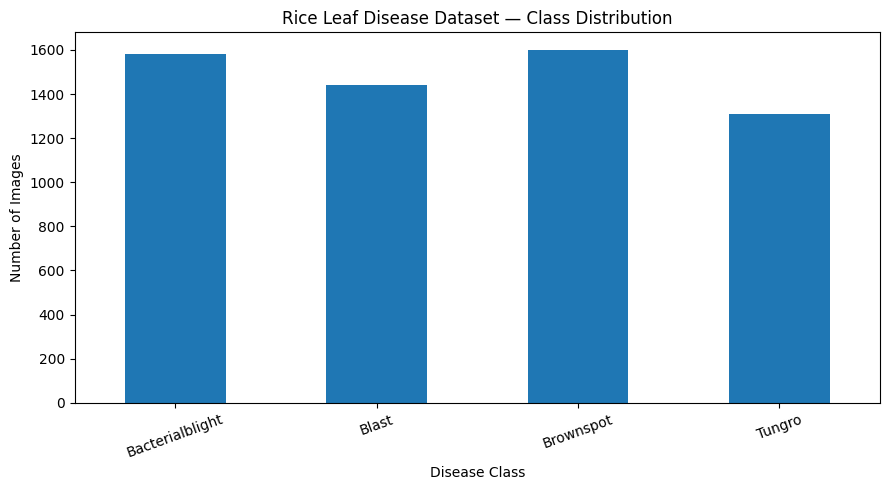

In [ ]:
import matplotlib.pyplot as plt

class_counts = df["label"].value_counts().reindex(CLASS_NAMES)

plt.figure(figsize=(9, 5))
class_counts.plot(kind="bar")
plt.title("Rice Leaf Disease Dataset — Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

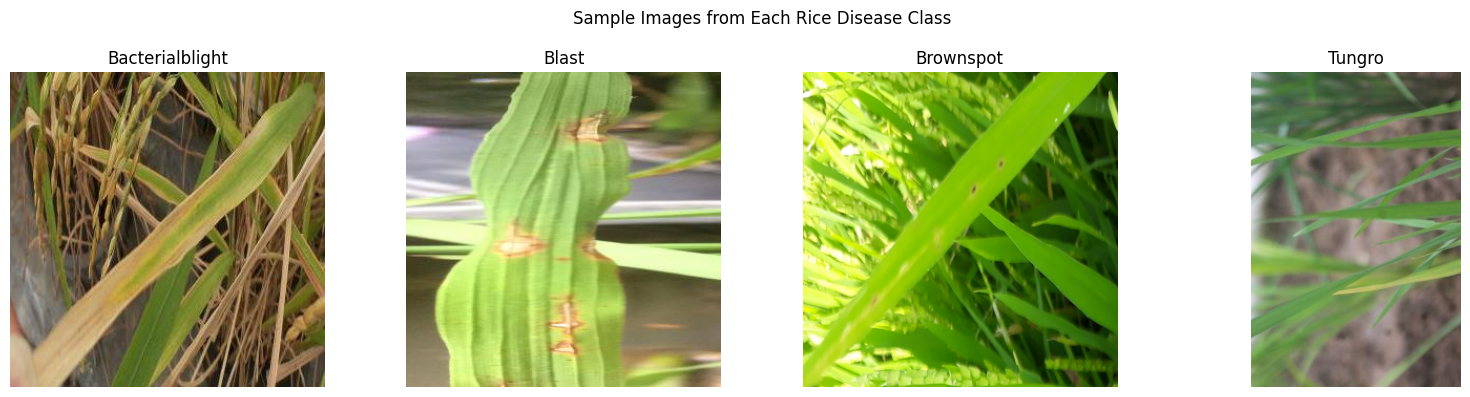

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, class_name in zip(axes, CLASS_NAMES):
    sample_path = df[df["label"] == class_name]["filepath"].iloc[0]

    with Image.open(sample_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Sample Images from Each Rice Disease Class")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total images:", len(train_df) + len(val_df) + len(test_df))

print("\nTraining distribution:")
print(train_df["label"].value_counts().reindex(CLASS_NAMES))

print("\nValidation distribution:")
print(val_df["label"].value_counts().reindex(CLASS_NAMES))

print("\nTesting distribution:")
print(test_df["label"].value_counts().reindex(CLASS_NAMES))

Training images: 4152
Validation images: 890
Testing images: 890
Total images: 5932

Training distribution:
label
Bacterialblight    1109
Blast              1008
Brownspot          1120
Tungro              915
Name: count, dtype: int64

Validation distribution:
label
Bacterialblight    237
Blast              216
Brownspot          240
Tungro             197
Name: count, dtype: int64

Testing distribution:
label
Bacterialblight    238
Blast              216
Brownspot          240
Tungro             196
Name: count, dtype: int64


In [ ]:
import numpy as np

class_to_index = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

for split_df in [train_df, val_df, test_df]:
    split_df["label_id"] = split_df["label"].map(class_to_index)

print("Class mapping:", class_to_index)
print(train_df[["filepath", "label", "label_id"]].head())

Class mapping: {'Bacterialblight': 0, 'Blast': 1, 'Brownspot': 2, 'Tungro': 3}
                                            filepath            label  \
0  /content/rice_leaf_dataset/Rice Leaf Disease I...            Blast   
1  /content/rice_leaf_dataset/Rice Leaf Disease I...        Brownspot   
2  /content/rice_leaf_dataset/Rice Leaf Disease I...  Bacterialblight   
3  /content/rice_leaf_dataset/Rice Leaf Disease I...  Bacterialblight   
4  /content/rice_leaf_dataset/Rice Leaf Disease I...           Tungro   

   label_id  
0         1  
1         2  
2         0  
3         0  
4         3  


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

tf.keras.utils.set_random_seed(SEED)

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
def load_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, tf.cast(label, tf.int32)


def create_dataset(dataframe, training=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label_id"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 130
Validation batches: 28
Testing batches: 28


In [ ]:
NUM_CLASSES = len(CLASS_NAMES)

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="data_augmentation")

base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))

x = data_augmentation(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from pathlib import Path

CHECKPOINT_PATH = "/content/best_rice_disease_model.keras"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        CHECKPOINT_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.6181 - loss: 0.9405
Epoch 1: val_loss improved from None to 0.28933, saving model to /content/best_rice_disease_model.keras

Epoch 1: finished saving model to /content/best_rice_disease_model.keras
130/130 ━━━━━━━━━━━━━━━━━━━━ 24s 109ms/step - accuracy: 0.7548 - loss: 0.6173 - val_accuracy: 0.8921 - val_loss: 0.2893 - learning_rate: 0.0010
Epoch 2/10
129/130 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8909 - loss: 0.3024
Epoch 2: val_loss improved from 0.28933 to 0.20270, saving model to /content/best_rice_disease_model.keras

Epoch 2: finished saving model to /content/best_rice_disease_model.keras
130/130 ━━━━━━━━━━━━━━━━━━━━ 11s 87ms/step - accuracy: 0.9029 - loss: 0.2714 - val_accuracy: 0.9360 - val_loss: 0.2027 - learning_rate: 0.0010
Epoch 3/10
129/130 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9203 - loss: 0.2117
Epoch 3: val_loss improved from 0.20270 to 0.17955, saving model to /content/best_rice_diseas

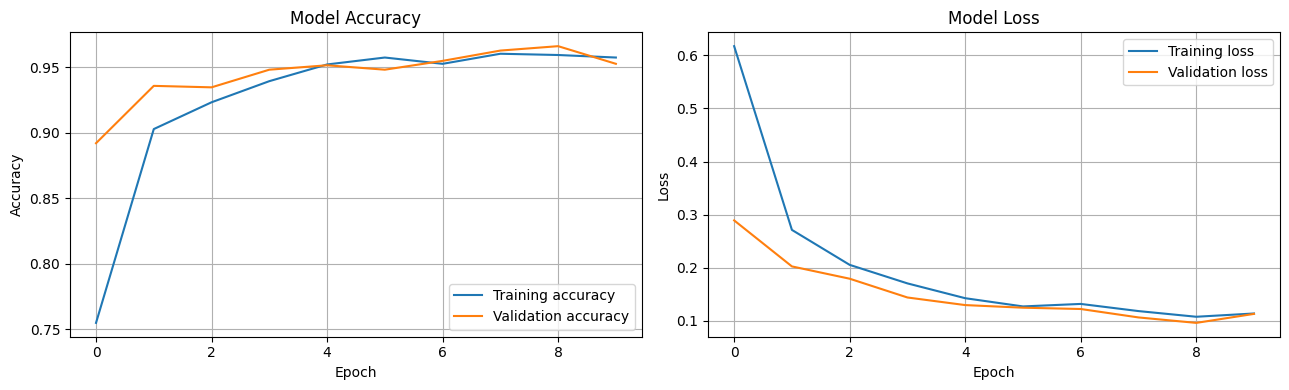

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
best_model = keras.models.load_model(CHECKPOINT_PATH)

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy percentage: {test_accuracy * 100:.2f}%")

28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.9652 - loss: 0.0992
Test loss: 0.0992
Test accuracy: 0.9652
Test accuracy percentage: 96.52%


In [ ]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix
)

y_true = test_df["label_id"].to_numpy()

probabilities = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

print("Overall test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro-F1:", round(
    f1_score(y_true, y_pred, average="macro", zero_division=0), 4
))
print("Weighted-F1:", round(
    f1_score(y_true, y_pred, average="weighted", zero_division=0), 4
))

28/28 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step
                 precision    recall  f1-score   support

Bacterialblight     0.9429    0.9706    0.9565       238
          Blast     0.9512    0.9028    0.9264       216
      Brownspot     0.9713    0.9875    0.9793       240
         Tungro     1.0000    1.0000    1.0000       196

       accuracy                         0.9652       890
      macro avg     0.9663    0.9652    0.9656       890
   weighted avg     0.9651    0.9652    0.9649       890

Overall test accuracy: 0.9652
Macro-F1: 0.9656
Weighted-F1: 0.9649


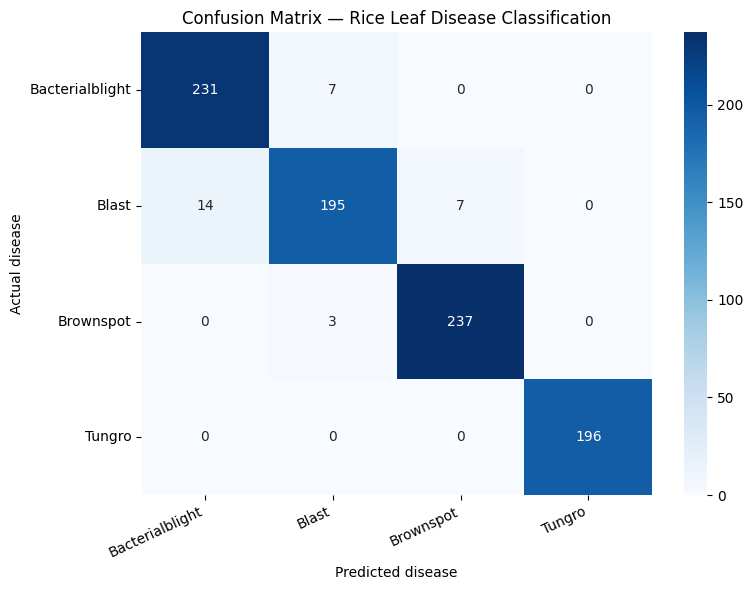

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Confusion Matrix — Rice Leaf Disease Classification")
plt.xlabel("Predicted disease")
plt.ylabel("Actual disease")
plt.xticks(rotation=25, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Misclassified test images: 31


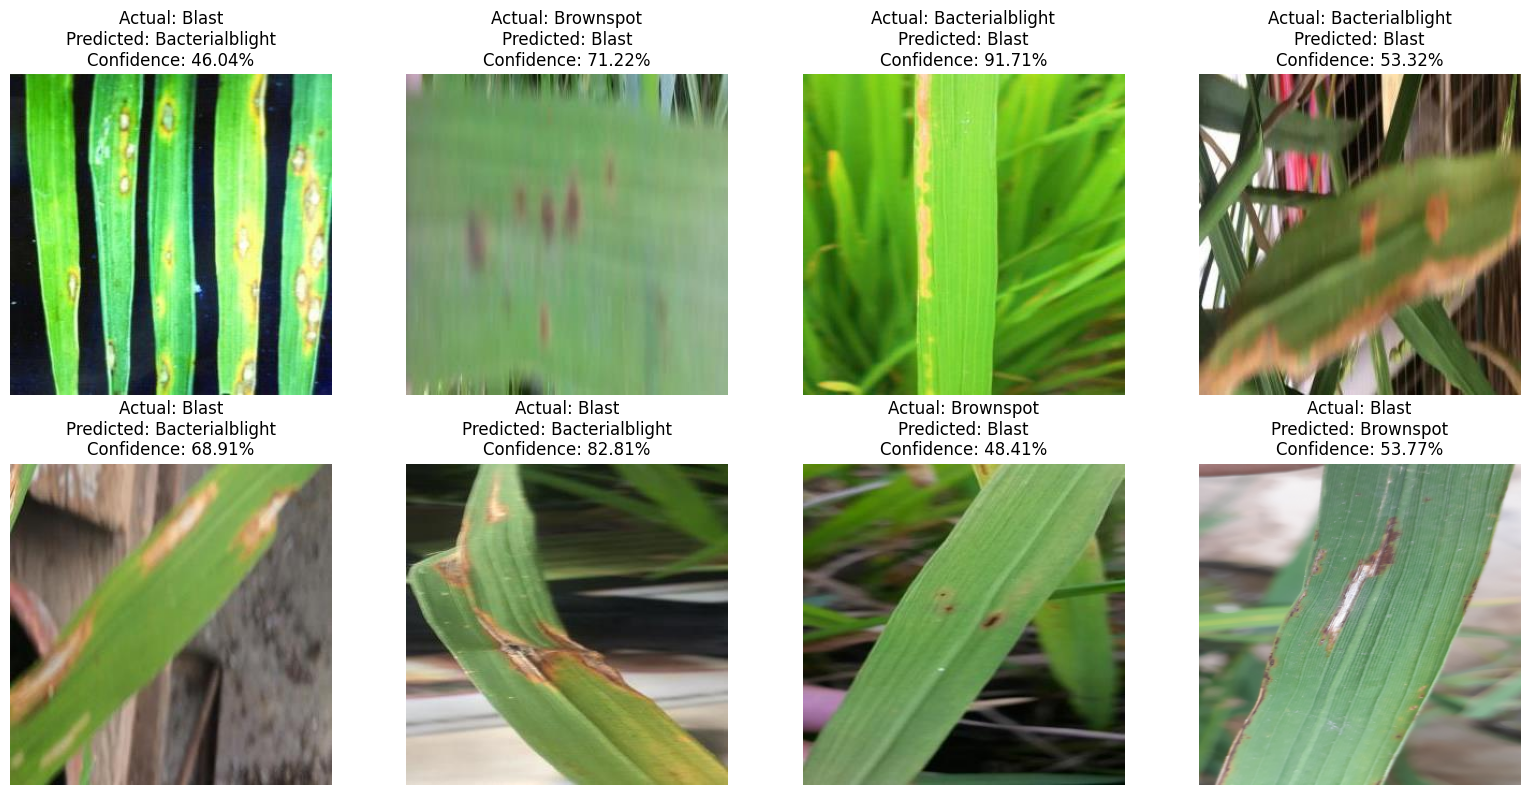

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

misclassified_indices = np.where(y_true != y_pred)[0]

print("Misclassified test images:", len(misclassified_indices))

if len(misclassified_indices) == 0:
    print("No misclassified images found in this test set.")
else:
    show_indices = misclassified_indices[:min(8, len(misclassified_indices))]

    fig, axes = plt.subplots(
        int(np.ceil(len(show_indices) / 4)),
        4,
        figsize=(16, 4 * int(np.ceil(len(show_indices) / 4)))
    )

    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, show_indices):
        image_path = test_df.iloc[idx]["filepath"]

        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))

        actual_name = index_to_class[int(y_true[idx])]
        predicted_name = index_to_class[int(y_pred[idx])]
        confidence = float(np.max(probabilities[idx]))

        ax.set_title(
            f"Actual: {actual_name}\n"
            f"Predicted: {predicted_name}\n"
            f"Confidence: {confidence:.2%}"
        )
        ax.axis("off")

    for ax in axes[len(show_indices):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
from collections import Counter

error_pairs = Counter()

for actual_id, predicted_id in zip(y_true, y_pred):
    if actual_id != predicted_id:
        error_pairs[(
            index_to_class[int(actual_id)],
            index_to_class[int(predicted_id)]
        )] += 1

print("Most frequent confusion pairs:")
for (actual, predicted), count in error_pairs.most_common(10):
    print(f"Actual {actual} → Predicted {predicted}: {count} images")

print("\nPotential explanations to investigate:")
print("- Similar lesion color, shape, or texture between disease classes.")
print("- Small or early-stage symptoms that are hard to distinguish.")
print("- Poor lighting, blur, cluttered backgrounds, or partially visible leaves.")
print("- Imbalanced class counts or insufficient representative training examples.")

Most frequent confusion pairs:
Actual Blast → Predicted Bacterialblight: 14 images
Actual Bacterialblight → Predicted Blast: 7 images
Actual Blast → Predicted Brownspot: 7 images
Actual Brownspot → Predicted Blast: 3 images

Potential explanations to investigate:
- Similar lesion color, shape, or texture between disease classes.
- Small or early-stage symptoms that are hard to distinguish.
- Poor lighting, blur, cluttered backgrounds, or partially visible leaves.
- Imbalanced class counts or insufficient representative training examples.


In [ ]:
import json
import pandas as pd
from pathlib import Path
from sklearn.metrics import classification_report

OUTPUT_DIR = Path("/content/rice_disease_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

best_model.save(OUTPUT_DIR / "rice_leaf_disease_mobilenetv2.keras")

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    OUTPUT_DIR / "classification_report.csv"
)

pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(OUTPUT_DIR / "confusion_matrix.csv")

with open(OUTPUT_DIR / "class_mapping.json", "w") as f:
    json.dump(class_to_index, f, indent=2)

print("Saved results to:", OUTPUT_DIR)
print("Model:", OUTPUT_DIR / "rice_leaf_disease_mobilenetv2.keras")

Saved results to: /content/rice_disease_results
Model: /content/rice_disease_results/rice_leaf_disease_mobilenetv2.keras


Saving Macro Rice Leaf Disease Study.png to Macro Rice Leaf Disease Study.png
Uploaded image: Macro Rice Leaf Disease Study.png
Image size: (1449, 1086)


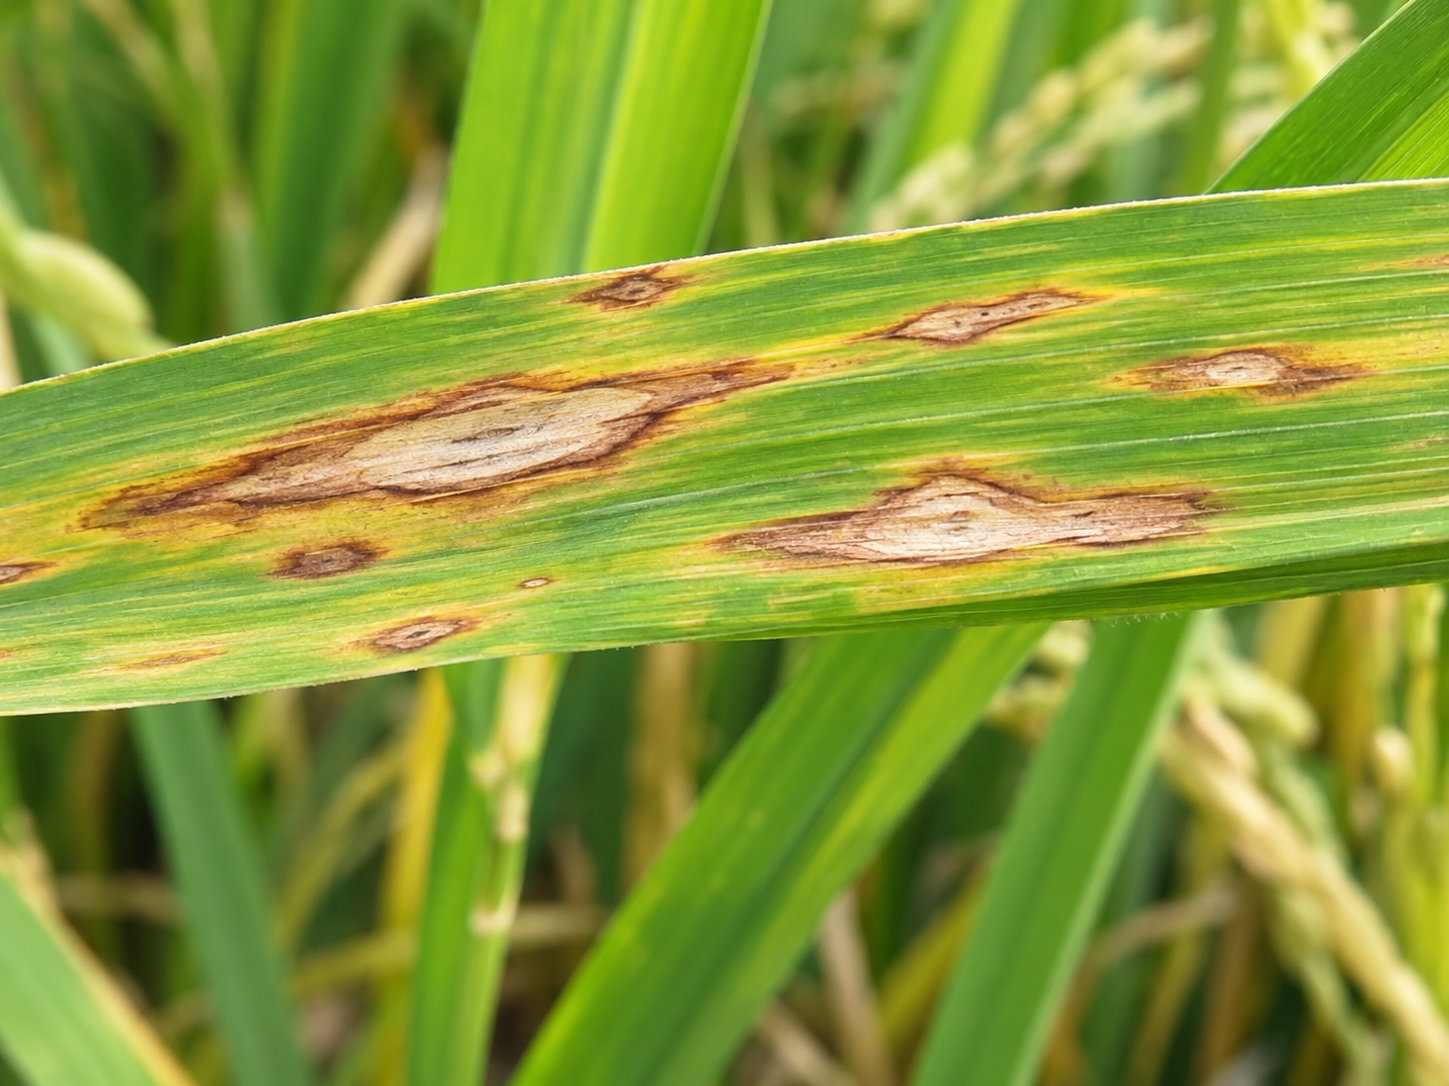

In [ ]:
from google.colab import files
from IPython.display import display
from PIL import Image
import io

uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload a rice leaf image.")

image_name = next(iter(uploaded))
test_image = Image.open(io.BytesIO(uploaded[image_name])).convert("RGB")

print("Uploaded image:", image_name)
print("Image size:", test_image.size)

display(test_image)

RICE LEAF DISEASE PREDICTION
Image: Macro Rice Leaf Disease Study.png
Predicted class: Blast
Model confidence: 87.00%


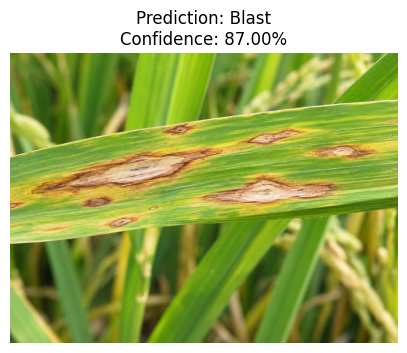

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path

MODEL_PATH = "/content/rice_disease_results/rice_leaf_disease_mobilenetv2.keras"

if not Path(MODEL_PATH).exists():
    raise FileNotFoundError(
        "Model not found. Run the training and save-model cells first."
    )

best_model = tf.keras.models.load_model(MODEL_PATH)

CLASS_NAMES = [
    "Bacterialblight",
    "Blast",
    "Brownspot",
    "Tungro"
]

IMG_SIZE = (224, 224)

# Prepare the image
image_resized = test_image.resize(IMG_SIZE)
image_array = np.array(image_resized, dtype=np.float32)
image_batch = np.expand_dims(image_array, axis=0)

# Predict
probabilities = best_model.predict(image_batch, verbose=0)[0]
predicted_index = int(np.argmax(probabilities))
predicted_class = CLASS_NAMES[predicted_index]
confidence = float(probabilities[predicted_index])

print("=" * 45)
print("RICE LEAF DISEASE PREDICTION")
print("=" * 45)
print("Image:", image_name)
print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.2%}")
print("=" * 45)

plt.figure(figsize=(5, 5))
plt.imshow(test_image)
plt.title(f"Prediction: {predicted_class}\nConfidence: {confidence:.2%}")
plt.axis("off")
plt.show()

,Disease,Probability
0,Blast,87.00%
1,Bacterialblight,12.82%
2,Brownspot,0.14%
3,Tungro,0.03%


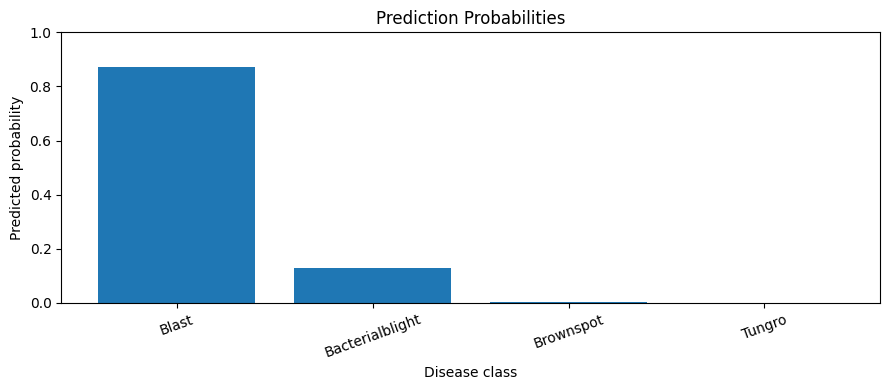

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Disease": CLASS_NAMES,
    "Probability": probabilities
}).sort_values("Probability", ascending=False)

display(
    results.assign(
        Probability=results["Probability"].map(lambda x: f"{x:.2%}")
    ).reset_index(drop=True)
)

plt.figure(figsize=(9, 4))
plt.bar(results["Disease"], results["Probability"])
plt.ylabel("Predicted probability")
plt.xlabel("Disease class")
plt.title("Prediction Probabilities")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()